# Assignment: Data Wrangling

### Reading material: `tidy_data.pdf`

**Q1.** This question provides some practice cleaning variables which have common problems.
1. For `./data/airbnb_hw.csv`, clean the `Price` variable as well as you can, and explain the choices you make. How many missing values do you end up with? (Hint: What happens to the formatting when a price goes over 999 dollars, say from 675 to 1,112?)
2. For the Minnesota police use of for data, `./data/mn_police_use_of_force.csv`, clean the `subject_injury` variable, handling the NA's; this gives a value `Yes` when a person was injured by police, and `No` when no injury occurred. What proportion of the values are missing? Is this a concern? Cross-tabulate your cleaned `subject_injury` variable with the `force_type` variable. Are there any patterns regarding when the data are missing?

**Q2.** Go to https://sharkattackfile.net/ and download their dataset on shark attacks (Hint: `GSAF5.xls`).

1. Open the shark attack file using Pandas. It is probably not a csv file, so `read_csv` won't work.
2. Drop any columns that do not contain data.
3. Clean the year variable. Describe the range of values you see. Filter the rows to focus on attacks since 1940. Are attacks increasing, decreasing, or remaining constant over time?
4. Clean the Age variable and make a histogram of the ages of the victims.
5. What proportion of victims are male?
6. Clean the `Type` variable so it only takes three values: Provoked and Unprovoked and Unknown. What proportion of attacks are unprovoked?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Meena Sakthi

**Date:** 9/2/2026

In [81]:
# Your Phase 1 solution to the problem goes here.
import pandas as pd
df = pd.read_csv("/content/A01-data-wrangling/data/airbnb_hw.csv")

# Question 1.1
print ("Q1.1")
print (f"Data type: ", df["Price"].dtype) #To check the data type (string, int, etc,.)
# Result = Data type is object

#Printing the min and max values to see if they are reasonable
print (f"Maximum value (before): ", df['Price'].max())
print (f"Minimum value (before): ", df['Price'].min())

# Max value = 999
# Min value = 1,000 (strings and integer)

df['Price'] = df['Price'].str.replace(',', '').astype(int) # Replacing the commas
print ("")
print (f"Max value (after): " , df['Price'].max())
print (f"Min value (after): " , df['Price'].min())

# Checks to see missing values
print("")
print(f"Missing values: ", df['Price'].isna().sum()) # Result = no missing values

#Question 1.2
df = pd.read_csv("/content/A01-data-wrangling/data/mn_police_use_of_force.csv")

print("")
print("Q1.2")
print(f"Data type: ", df["subject_injury"].dtype) # Checking the data type
print(df.subject_injury.head(15)) # Checking the values
print(f"Rows and columns:", df.shape) # Check the number of rows to calculate proportion

# Calculating the proportion missing and explanation for any patterns
print(f"Missing values: ", df['subject_injury'].isna().sum())
print( f"Proportion missing: ", df['subject_injury'].isna().sum()/df.shape[0])
print("")
print("About 76.2% of the subject injury values are missing, this is a huge concern")
print("")
print(pd.crosstab(df["force_type"], df["subject_injury"], dropna=False))
print("")
print("Yes, there is a pattern regarding when the data is missing and it is related to the type of force."
      "When the force type is related to a severe restraint technique such as bodily force, chemical restraint,"
      "maximal restraint technique, taser, etc., the missing values are higher." )







Q1.1
Data type:  object
Maximum value (before):  999
Minimum value (before):  1,000

Max value (after):  10000
Min value (after):  10

Missing values:  0

Q1.2
Data type:  object
0     NaN
1     NaN
2     NaN
3     NaN
4     NaN
5     NaN
6     NaN
7     NaN
8     NaN
9      No
10     No
11    Yes
12    Yes
13    Yes
14     No
Name: subject_injury, dtype: object
Rows and columns: (12925, 13)
Missing values:  9848
Proportion missing:  0.7619342359767892

About 76.2% of the subject injury values are missing, this is a huge concern

subject_injury                 No   Yes   NaN
force_type                                   
Baton                           0     2     2
Bodily Force                 1093  1286  7051
Chemical Irritant             131    41  1421
Firearm                         2     0     0
Gun Point Display              33    44    27
Improvised Weapon              34    40    74
Less Lethal                     0     0    87
Less Lethal Projectile          1     2     0
Maxi

Q2.1

Q2.2
Index(['Date', 'Year', 'Type', 'Country', 'State', 'Location', 'Activity',
       'Name', 'Sex', 'Age', 'Injury', 'Fatal Y/N', 'Time', 'Species ',
       'Source', 'pdf', 'href formula', 'href', 'Case Number', 'Case Number.1',
       'original order', 'Unnamed: 21', 'Unnamed: 22'],
      dtype='object')
(7117, 21)

Q2.3
Data type:  float64
The year ranges from  0.0 to 2026.0
Minimum and maximum values of the years (after filtering)
1940.0
2026.0

Year
1940.0     24
1941.0     27
1942.0     41
1943.0     28
1944.0     31
         ... 
2022.0     98
2023.0    109
2024.0     52
2025.0     69
2026.0     53
Name: count, Length: 87, dtype: int64
The overall trend is that the number of attacks are increased since the 1940s. However, the number varies from year to year as they have peaks and also a recent decrease

Q2.4
Data type:  object
Abnormal values
['?' '43' '27' '71' '21' '69' '31' '13' '12' '17' '35' "20's" '19' '11'
 '20' '38' '39' '16' '22' '30+' "50's" '55' '26' '56' '24'

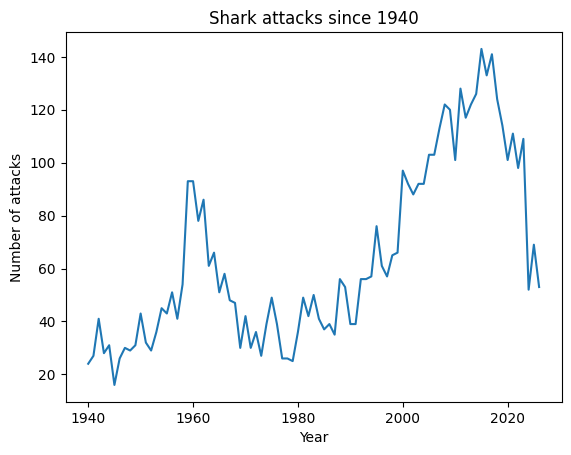

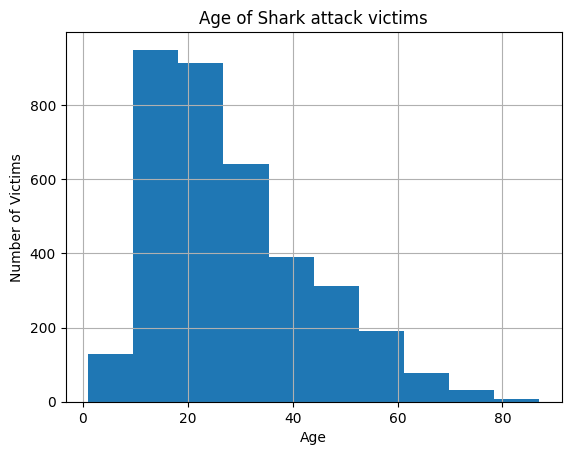


Q2.5
Male Proportion:  0.785522307830138

Q2.6
0    Unprovoked
1    Unprovoked
2      Provoked
3      Provoked
4    Unprovoked
Name: Type, dtype: object

Unique values:  ['Unprovoked' 'Provoked' 'Questionable' 'UNprovoked' 'unprovoked'
 ' Provoked' 'Watercraft' 'Sea Disaster' nan '?' 'Unconfirmed'
 'Unverified' 'Invalid' 'Under investigation' 'Boat']
Type
Unprovoked             4161
Provoked                526
Invalid                 402
Watercraft              280
Sea Disaster            156
Questionable             27
Boat                      7
 Provoked                 2
unprovoked                1
UNprovoked                1
Unconfirmed               1
?                         1
Unverified                1
Under investigation       1
Name: count, dtype: int64
Type
Unprovoked    4163
Unknown        890
Provoked       528
Name: count, dtype: int64
Proportion of attacks that were unprovoked:  0.7459236695932628


In [82]:
# Question 2.1
df = pd.read_excel("/content/A01-data-wrangling/GSAF5.xls")
print ("Q2.1")

# Question 2.2
print("")
print("Q2.2")
df.head()
print(df.columns) # Checking to see which columns don't contain values
df = df.drop(columns=['Unnamed: 21', 'Unnamed: 22']) # Dropping the columns with no values
print(df.shape) # Making sure the dimensions of the data has changed

# Question 2.3
print("")
print("Q2.3")
print(f"Data type: ", df["Year"].dtype)

# Printing the range using min and max
print("The year ranges from ", df["Year"].min(), "to", df["Year"].max())

# Filtering the year and checking the range of the year
df_1940 = df[df["Year"] >= 1940].copy()
print("Minimum and maximum values of the years (after filtering)")
print(df_1940["Year"].min())
print(df_1940["Year"].max())
print("")

# Checking the relationship between the year and the number of attacks
print(df_1940["Year"].value_counts().sort_index())
attacksperyear = df_1940["Year"].value_counts().sort_index()
attacksperyear.plot(xlabel ="Year", ylabel="Number of attacks", title="Shark attacks since 1940") #Plottinng to further check
print("The overall trend is that the number of attacks are increased since the 1940s. However, the number varies from year to year as they have peaks and also a recent decrease")


# Question 2.4
print("")
print ("Q2.4")
print(f"Data type: ", df_1940["Age"].dtype) # chekcing the data type to correct
print("Abnormal values")
print(df_1940["Age"].unique()) # checking for any abnormal values
df_1940["Age"] = pd.to_numeric(df_1940["Age"], errors='coerce') #Changing everything to numeric values
print(f"Data type (after clean): ", df_1940["Age"].dtype) # Confirming the cleaned data type

# Checking the range to confirm no discrepencies
print("The age ranges from ", df_1940["Age"].min(), "to", df_1940["Age"].max())

#Plotting the histogram of the age
import matplotlib.pyplot as plt
plt.figure()
df_1940["Age"].hist()
plt.xlabel("Age")
plt.ylabel("Number of Victims")
plt.title("Age of Shark attack victims")
plt.show()

#Question 2.5
print("")
print ("Q2.5")
df_1940['Sex'].head() #Checking the format of the values

#Calculating the proportion of males
males = (df_1940["Sex"] == "M").sum()
total = len(df_1940["Sex"])
proportion_male = males/total
print(f"Male Proportion: ", proportion_male)

#Question 2.6
print("")
print ("Q2.6")
print(df_1940["Type"].head()) # Checking the formal of the values
print("")
print(f"Unique values: " , df_1940["Type"].unique()) # Checking for abnormal values
print(df_1940["Type"].value_counts())

# Removing spelling errors and replacing the variable names
df_1940["Type"]=df["Type"].str.strip().str.lower()

def clean_type(x):
  if x == "provoked":
    return "Provoked"
  elif x == "unprovoked":
    return "Unprovoked"
  else:
    return "Unknown"

df_1940["Type"] = df_1940["Type"].apply(clean_type)
print(df_1940["Type"].value_counts())

# Calculating the proportion
print(f"Proportion of attacks that were unprovoked: ", (df_1940["Type"] == "Unprovoked").sum()/len(df_1940["Type"]))






## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 1f3e9891
- **AI tool and model used:** ChatGPT

### *Prompts used

1. (I uploaded a copy of the notebook) Audit and revise my Phase 1 solution. Check if my code correctly answers each question and give me a numbered list of specific changes.
2. Show me the exact code changes you recommend for each issue mentioned. For each change, show my current approach and the revised code. Don't change parts of my Phase 1 solution that are already correct.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

I audited your Phase 1 notebook against the assignment questions. Most of your approach is good, but there are a few places where the code either does not fully satisfy the question or could give a misleading result.

Here is a concise numbered list you can paste directly into “AI-proposed changes”:

Q1.1 – Make the Price cleaning more robust. After removing commas, use pd.to_numeric(..., errors="coerce") instead of .astype(int). This will convert invalid or unexpected price entries to NaN rather than causing an error, and then the number of missing values can be checked reliably.
Q1.2 – Actually create a cleaned subject_injury variable. The current code calculates the missing values but never cleans the variable as requested. Create a separate cleaned column that handles the missing values while keeping the original column available for analyzing missingness.
Q1.2 – Improve the missingness analysis by comparing percentages rather than only counts. The cross-tabulation shows large numbers of missing values for categories such as Bodily Force, but this may partly be because those force types occur more often. Calculate the proportion missing within each force_type before concluding which force types have unusually high missingness.
Q2.2 – Drop empty columns programmatically instead of naming only Unnamed: 21 and Unnamed: 22. Use a method that removes columns containing no data, such as dropna(axis=1, how="all"). This directly answers the instruction to drop any columns that do not contain data.
Q2.3 – Explicitly clean Year before analyzing it. Convert Year with pd.to_numeric(..., errors="coerce"), inspect invalid or missing years, and then filter for years greater than or equal to 1940. The current data show a minimum year of 0, which is clearly not a valid attack year and should be discussed as part of the cleaning.
Q2.4 – Improve the cleaning of Age. pd.to_numeric(..., errors="coerce") correctly handles simple numeric ages, but it discards values such as "20's", "30+", "mid-20s", and age ranges. Either explain that these ambiguous values are intentionally treated as missing or convert reasonable cases to approximate numeric ages before making the histogram.
Q2.5 – Clean Sex and use an appropriate denominator when calculating the male proportion. Strip spaces and standardize capitalization, then calculate the proportion male among records with a valid known sex rather than dividing by every attack row, since missing or unknown sex values should not automatically count as non-male.
Q2.6 – Fix the dataframe reference when cleaning Type. Change df_1940["Type"] = df["Type"].str.strip().str.lower() to df_1940["Type"] = df_1940["Type"].str.strip().str.lower(). The current version happens to align by index, but it unnecessarily pulls values from the unfiltered dataframe and could cause errors or unexpected behavior if the indices change.

One thing I would not change is your basic Q2.6 classification: mapping the different spellings of provoked/unprovoked and putting everything else into "Unknown" correctly produces the requested three categories. Your resulting unprovoked proportion of about 0.746 (74.6%) is consistent with that definition.

Also, your 76.2% missing calculation in Q1.2 is correct. The problem is mainly that the next cleaning step is missing and your interpretation of the force-type pattern should be based on percentages, not raw counts.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|------|---|
| 1 |  Accept   | Safer way to conver price to numbers. I checked min, max, and missing balues after cleaning |
| 2 |  Modify   | Missing doesn't necessarily means "No", so I used "Unknown". I checked missing proportions for each force type |
| 3 |  Accept   | Automatically removes all empty columns and I also checked the data shape after removing them|
| 4 |  Accept   | This can help identify invalid or missing year before filtering. I checked the year range before and after filtering |
| 5 |  Accept   | It shows how many clear ages became missing after cleaning. I checked the missing values after converting |
| 6 |  Accept   | This is to make sure that missing or unknown values are not counted when I calculate the male proportion. I also checked the final proportion |
| 7 |  Accept   | I changed df to df_1940 because that is the data that is being analyzed (careless mistake). I checked the type categories after|

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [83]:
# Your Phase 2 solution to the problem goes here.
import pandas as pd
df = pd.read_csv("/content/A01-data-wrangling/data/airbnb_hw.csv")

# Question 1.1
print ("Q1.1")
print (f"Data type: ", df["Price"].dtype) #To check the data type (string, int, etc,.)
# Result = Data type is object

#Printing the min and max values to see if they are reasonable
print (f"Maximum value (before): ", df['Price'].max())
print (f"Minimum value (before): ", df['Price'].min())

# Max value = 999
# Min value = 1,000 (strings and integer)

df['Price'] = df['Price'].str.replace(',', '') # Replacing the commas
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

print ("")
print (f"Max value (after): " , df['Price'].max())
print (f"Min value (after): " , df['Price'].min())

# Checks to see missing values
print("")
print(f"Missing values: ", df['Price'].isna().sum()) # Result = no missing values

#Question 1.2
df = pd.read_csv("/content/A01-data-wrangling/data/mn_police_use_of_force.csv")

print("")
print("Q1.2")
print(f"Data type: ", df["subject_injury"].dtype) # Checking the data type
print(df.subject_injury.head(15)) # Checking the values
print(f"Rows and columns:", df.shape) # Check the number of rows to calculate proportion

# Calculating the proportion missing and explanation for any patterns
print(f"Missing values: ", df['subject_injury'].isna().sum())
print( f"Proportion missing: ", df['subject_injury'].isna().sum()/df.shape[0])
print("")
print("About 76.2% of the subject injury values are missing, this is a huge concern")
print("")

# Cleaning the missing values
df["subject_injury_clean"] = df["subject_injury"].fillna("Unknown")

print(pd.crosstab(df["force_type"], df["subject_injury_clean"]))
print("")

# Checking the proportion missing for each force type
missing_by_force = df.groupby("force_type")["subject_injury"].apply(
    lambda x: x.isna().mean()
)

print(missing_by_force.sort_values(ascending=False))
print("")

print("Yes, there is a pattern regarding when the data is missing because the proportion of missing "
      "subject injury values differs depending on the force type.")

Q1.1
Data type:  object
Maximum value (before):  999
Minimum value (before):  1,000

Max value (after):  10000
Min value (after):  10

Missing values:  0

Q1.2
Data type:  object
0     NaN
1     NaN
2     NaN
3     NaN
4     NaN
5     NaN
6     NaN
7     NaN
8     NaN
9      No
10     No
11    Yes
12    Yes
13    Yes
14     No
Name: subject_injury, dtype: object
Rows and columns: (12925, 13)
Missing values:  9848
Proportion missing:  0.7619342359767892

About 76.2% of the subject injury values are missing, this is a huge concern

subject_injury_clean           No  Unknown   Yes
force_type                                      
Baton                           0        2     2
Bodily Force                 1093     7051  1286
Chemical Irritant             131     1421    41
Firearm                         2        0     0
Gun Point Display              33       27    44
Improvised Weapon              34       74    40
Less Lethal                     0       87     0
Less Lethal Projectile 

Q2.1

Q2.2
Index(['Date', 'Year', 'Type', 'Country', 'State', 'Location', 'Activity',
       'Name', 'Sex', 'Age', 'Injury', 'Fatal Y/N', 'Time', 'Species ',
       'Source', 'pdf', 'href formula', 'href', 'Case Number', 'Case Number.1',
       'original order', 'Unnamed: 21', 'Unnamed: 22'],
      dtype='object')
(7117, 23)

Q2.3
Data type:  float64
The year ranges from  0.0 to 2026.0
Missing years: 2
Years below 1940: 1534
Minimum and maximum values of the years (after filtering)
1940.0
2026.0

Year
1940.0     24
1941.0     27
1942.0     41
1943.0     28
1944.0     31
         ... 
2022.0     98
2023.0    109
2024.0     52
2025.0     69
2026.0     53
Name: count, Length: 87, dtype: int64
The overall trend is that the number of attacks are increased since the 1940s. However, the number varies from year to year as they have peaks and also a recent decrease

Q2.4
Data type:  object
Abnormal values
['?' '43' '27' '71' '21' '69' '31' '13' '12' '17' '35' "20's" '19' '11'
 '20' '38' '39' '1

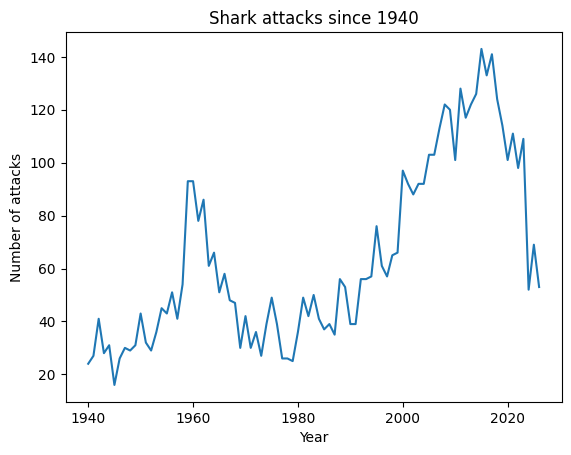

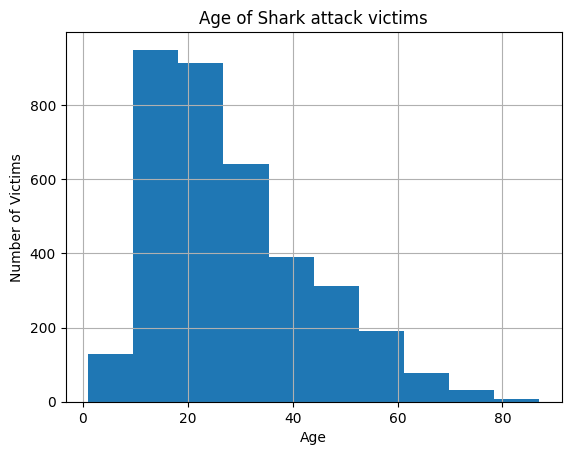


Q2.5
Male Proportion:  0.8571707317073171

Q2.6
0    Unprovoked
1    Unprovoked
2      Provoked
3      Provoked
4    Unprovoked
Name: Type, dtype: object

Unique values:  ['Unprovoked' 'Provoked' 'Questionable' 'UNprovoked' 'unprovoked'
 ' Provoked' 'Watercraft' 'Sea Disaster' nan '?' 'Unconfirmed'
 'Unverified' 'Invalid' 'Under investigation' 'Boat']
Type
Unprovoked             4161
Provoked                526
Invalid                 402
Watercraft              280
Sea Disaster            156
Questionable             27
Boat                      7
 Provoked                 2
unprovoked                1
UNprovoked                1
Unconfirmed               1
?                         1
Unverified                1
Under investigation       1
Name: count, dtype: int64
Type
Unprovoked    4163
Unknown        890
Provoked       528
Name: count, dtype: int64
Proportion of attacks that were unprovoked:  0.7459236695932628


In [84]:
# Question 2.1
df = pd.read_excel("/content/A01-data-wrangling/GSAF5.xls")
print ("Q2.1")

# Question 2.2
print("")
print("Q2.2")
df.head()
print(df.columns) # Checking to see which columns don't contain values
df = df.dropna(axis=1, how="all") # Dropping the columns with no values
print(df.shape) # Making sure the dimensions of the data has changed

# Question 2.3
print("")
print("Q2.3")
print(f"Data type: ", df["Year"].dtype)

df["Year"] = pd.to_numeric(df["Year"], errors="coerce")

# Printing the range using min and max
print("The year ranges from ", df["Year"].min(), "to", df["Year"].max())

print("Missing years:", df["Year"].isna().sum())
print("Years below 1940:", (df["Year"] < 1940).sum())

# Filtering the year and checking the range of the year
df_1940 = df[df["Year"] >= 1940].copy()
print("Minimum and maximum values of the years (after filtering)")
print(df_1940["Year"].min())
print(df_1940["Year"].max())
print("")

# Checking the relationship between the year and the number of attacks
print(df_1940["Year"].value_counts().sort_index())
attacksperyear = df_1940["Year"].value_counts().sort_index()
attacksperyear.plot(xlabel ="Year", ylabel="Number of attacks", title="Shark attacks since 1940") #Plottinng to further check
print("The overall trend is that the number of attacks are increased since the 1940s. However, the number varies from year to year as they have peaks and also a recent decrease")


# Question 2.4
print("")
print ("Q2.4")
print(f"Data type: ", df_1940["Age"].dtype) # chekcing the data type to correct
print("Abnormal values")
print(df_1940["Age"].unique()) # checking for any abnormal values
df_1940["Age"] = pd.to_numeric(df_1940["Age"], errors='coerce') #Changing everything to numeric values
print(f"Data type (after clean): ", df_1940["Age"].dtype) # Confirming the cleaned data type
print("Missing/unclear ages after cleaning:", df_1940["Age"].isna().sum())

# Checking the range to confirm no discrepencies
print("The age ranges from ", df_1940["Age"].min(), "to", df_1940["Age"].max())

#Plotting the histogram of the age
import matplotlib.pyplot as plt
plt.figure()
df_1940["Age"].hist()
plt.xlabel("Age")
plt.ylabel("Number of Victims")
plt.title("Age of Shark attack victims")
plt.show()

#Question 2.5
print("")
print ("Q2.5")
df_1940['Sex'].head() #Checking the format of the values

df_1940["Sex"] = df_1940["Sex"].str.strip().str.upper()

known_sex = df_1940["Sex"].isin(["M", "F"])

#Calculating the proportion of males
males = (df_1940.loc[known_sex, "Sex"] == "M").sum()
total = known_sex.sum()
proportion_male = males/total
print(f"Male Proportion: ", proportion_male)

#Question 2.6
print("")
print ("Q2.6")
print(df_1940["Type"].head()) # Checking the formal of the values
print("")
print(f"Unique values: " , df_1940["Type"].unique()) # Checking for abnormal values
print(df_1940["Type"].value_counts())

# Removing spelling errors and replacing the variable names
df_1940["Type"]=df_1940["Type"].str.strip().str.lower()

def clean_type(x):
  if x == "provoked":
    return "Provoked"
  elif x == "unprovoked":
    return "Unprovoked"
  else:
    return "Unknown"

df_1940["Type"] = df_1940["Type"].apply(clean_type)
print(df_1940["Type"].value_counts())

# Calculating the proportion
print(f"Proportion of attacks that were unprovoked: ", (df_1940["Type"] == "Unprovoked").sum()/len(df_1940["Type"]))

### *Reflection on AI assistance
In your own words without generative AI.

The main improvements were focused on making my data cleaning and analysis more reliable. The AI suggested 7 changes. Some of the main changes included using a safer method to convert the price column to numeric values, which improved how I handled the missing subject_injury data. It also automatically removed completely empty columns and also improving the proportion calulation of male victims by excluding missing or unknown values which is something I was unaware of. I also corrected the dataframe reference used when cleaning the Type column. One limitation I noticed with the AI suggestion was that it originally recomended replacing missing subject_injury values with "No". I didn't think this was a good assumption, hence I modified the suggestion and used "Unknown" instead. I verified the final solution by running all the revised code and checking the results. A remaining concers that I have is that the datasets still contain a lot of missing or unclear information. For example, about 76.2% of the subject_injury values are missing and some age values cannot be converted directly to a specific age in number. These limitations could still affect the conclusions drawn from the data